# Rayleigh–Kuo Eigenvalue Solver 
We solve

$$ (U-c)\,(\psi'' - \alpha^2\psi) + (\beta - U'')\,\psi = 0 $$



**We follow these steps to reproduce the method of Dickinson and Clare (1973):**
1. Rewrite as $\psi'' = Q\psi$ with $\;Q = \dfrac{\beta - U''}{c-U} + \alpha^2$.
2. Discretise with the **4th-order (Numerov) tridiagonal stencil**. As explained in appendix of the paper.
3. Replace the first/last rows with **radiation boundary conditions**.
4. The system is $A(c)\,\psi = 0$; non-trivial solutions require $\det A(c)=0$.
5. Find the complex root $c$ of $f(c)=\det A(c)$ (Newton), then recover the
   eigenfunction by **inverse iteration**.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig, solve_banded
from pathlib import Path
np.set_printoptions(suppress=True)

## 1. Parameters and grid

The velocity profile is the hyperbolic-tangent shear layer
$U = \tfrac12(1+\tanh y)$, which has an inflection point at $y=0$ (a necessary
condition for instability). Its curvature is $U'' = -\tanh y \,\operatorname{sech}^2 y$.

In [24]:
# Physical parameters
alpha2 = 0.1     # alpha^2  (square of the wavenumber)
beta   = 0.0     # beta-plane parameter
alpha  = np.sqrt(alpha2)

# Grid
ymin, ymax = -10.0, 10.0
N = 2500
Y = np.linspace(ymin, ymax, N)
h = Y[1] - Y[0]

# Shear profile
U     = 0.5 * (1.0 + np.tanh(Y))
sech2 = 1.0 / np.cosh(Y)**2
Uyy   = -np.tanh(Y) * sech2

print(f"alpha = {alpha:.4f}, alpha^2 = {alpha2}, beta = {beta}")
print(f"grid: N = {N}, y in [{ymin}, {ymax}], h = {h:.5f}")

alpha = 0.3162, alpha^2 = 0.1, beta = 0.0
grid: N = 2500, y in [-10.0, 10.0], h = 0.00800


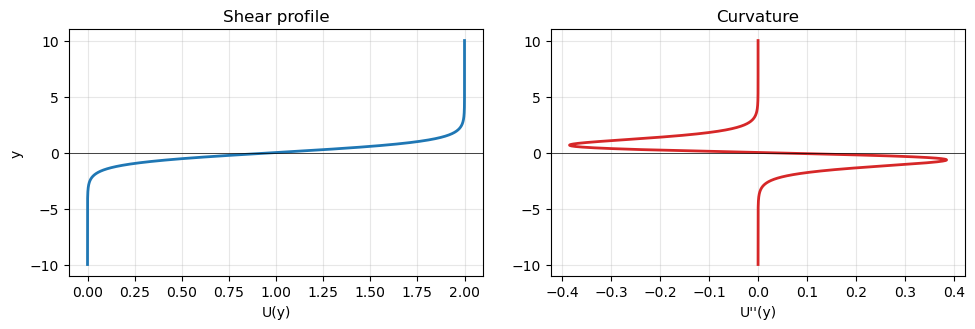

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(U, Y, lw=2);   ax[0].set(xlabel="U(y)",  ylabel="y", title="Shear profile")
ax[1].plot(Uyy, Y, lw=2, color="C3"); ax[1].set(xlabel="U''(y)", title="Curvature")
for a in ax: a.grid(alpha=.3); a.axhline(0, color='k', lw=.5)
plt.tight_layout(); plt.show()

## 2. Initial guess from a linear eigenvalue problem


In [4]:
def initial_guess(Nc,alpha2,beta):
    """Coarse 2nd-order generalized-eigenvalue solve -> most unstable c."""
    Yc = np.linspace(ymin, ymax, Nc)
    hc = Yc[1] - Yc[0]
    Uc   = 0.5 * (1.0 + np.tanh(Yc))
    Uyyc = -np.tanh(Yc) / np.cosh(Yc)**2
    main = -2.0*np.ones(Nc); off = np.ones(Nc-1)
    D2  = (np.diag(main) + np.diag(off, 1) + np.diag(off, -1)) / hc**2
    Lap = D2 - alpha2*np.eye(Nc)
    L = np.diag(Uc) @ Lap + np.diag(beta - Uyyc)
    w, _ = eig(L, Lap)
    w = w[np.isfinite(w)]
    # keep physically reasonable phase speeds (within the velocity range)
    sel = (w.real > Uc.min() - 0.2) & (w.real < Uc.max() + 0.2)
    if np.any(sel): w = w[sel]
    return w[np.argmax(w.imag)]

c0 = initial_guess(400,alpha2,beta)
print(f"initial guess  c0 = {c0.real:.6f} + {c0.imag:.6f} i")

initial guess  c0 = 0.500000 + 0.278740 i


## 3. The coefficient $Q(c)$

$$ Q(y;c) = \frac{\beta - U''(y)}{\,c - U(y)\,} + \alpha^2 $$

Because $c$ is complex (with $c_i\neq 0$ for an unstable mode), the denominator
$c-U$ never vanishes, so $Q$ is smooth across the critical layer.

In [5]:
def Qfunc(c):
    """Coefficient Q"""
    return (beta - Uyy) / (c - U) + alpha2

def branch_decay(arg):
    l = np.sqrt(complex(arg))
    return -l if l.imag > 0 else l

def build_A(c):
    """Return the tridiagonal matrix"""
    Q = Qfunc(c)
    h2 = h * h
    diag = np.empty(N, dtype=complex)
    sub  = np.zeros(N, dtype=complex)
    sup  = np.zeros(N, dtype=complex)

    # Interior rows
    diag[1:-1] = -2.0 - (5.0/6.0) * Q[1:-1] * h2
    sub[1:-1]  =  1.0 - Q[:-2] * h2 / 12.0      # coeff of psi[n-1]  (uses Q[n-1])
    sup[1:-1]  =  1.0 - Q[2:]  * h2 / 12.0      # coeff of psi[n+1]  (uses Q[n+1])

    # Radiation boundary-condition rows
    l_minus = branch_decay(beta / (-c)      - alpha2)
    l_plus  = branch_decay(beta / (1.0 - c) - alpha2)

    diag[0]  = -1.0/h - 1j*l_minus/2.0          # lower boundary
    sup[0]   =  1.0/h - 1j*l_minus/2.0
    sub[-1]  = -1.0/h + 1j*l_plus/2.0           # upper boundary
    diag[-1] =  1.0/h + 1j*l_plus/2.0
    return sub, diag, sup

## 4. The determinant $f(c)=\det A(c)$


In [6]:
def det_A(c):
    sub, diag, sup = build_A(c)
    f_prev2 = 1.0 + 0j        # f_0
    f_prev1 = diag[0]         # f_1
    for i in range(1, N):
        f = diag[i]*f_prev1 - sub[i]*sup[i-1]*f_prev2
        m = abs(f)
        if m > 1e150 or (0.0 < m < 1e-150):   # rescale: preserves the roots
            f /= m; f_prev1 /= m
        f_prev2, f_prev1 = f_prev1, f
    return f_prev1

## 5. **4th-order** method: Newton iteration

We refine the guess to the **4th-order** eigenvalue.

In [7]:
def find_eigenvalue(c0, tol=1e-11, maxit=60, verbose=True):
    c = complex(c0)
    for it in range(1, maxit+1):
        f  = det_A(c)
        dc = 1e-7 * (1.0 + abs(c))
        fp = (det_A(c + dc) - det_A(c - dc)) / (2.0*dc)
        step = f / fp
        c -= step
        if verbose:
            print(f"  iter {it:2d}:  c = {c.real:.10f} + {c.imag:.10f} i   |step| = {abs(step):.2e}")
        if abs(step) < tol * (1.0 + abs(c)):
            break
    return c

print("Newton iterations (4th-order determinant):")
c = find_eigenvalue(c0)
print(f"\nEigenvalue      c   = {c.real:.10f} + {c.imag:.10f} i")
print(f"Phase speed     c_r = {c.real:.10f}")
print(f" c_i = {c.imag:.10f}")
print(f"Temporal growth a*ci= {alpha*c.imag:.10f}")
print(f"Unstable mode?      {'YES' if c.imag > 0 else 'no'}")

Newton iterations (4th-order determinant):
  iter  1:  c = 0.8493281301 + 0.4585436870 i   |step| = 3.93e-01
  iter  2:  c = 1.0051689394 + 0.4257933159 i   |step| = 1.59e-01
  iter  3:  c = 0.9999296063 + 0.4127913493 i   |step| = 1.40e-02
  iter  4:  c = 0.9999999947 + 0.4128641851 i   |step| = 1.01e-04
  iter  5:  c = 1.0000000000 + 0.4128641852 i   |step| = 5.30e-09
  iter  6:  c = 1.0000000000 + 0.4128641852 i   |step| = 7.33e-13

Eigenvalue      c   = 1.0000000000 + 0.4128641852 i
Phase speed     c_r = 1.0000000000
 c_i = 0.4128641852
Temporal growth a*ci= 0.1305591190
Unstable mode?      YES


## 6. Eigenfunction by inverse iteration

At the eigenvalue $A(c)$ is (numerically) singular. Repeatedly solving
$A(c)\,x_{k+1}=x_k$ amplifies the null-space vector, which converges to the
eigenfunction $\psi(y)$. We use the banded solver for the tridiagonal system.

In [8]:
def eigenfunction(c, iters=80, seed=0):
    sub, diag, sup = build_A(c)
    ab = np.zeros((3, N), dtype=complex)   # banded storage for solve_banded
    ab[0, 1:]  = sup[:-1]                   # super-diagonal
    ab[1, :]   = diag                       # diagonal
    ab[2, :-1] = sub[1:]                    # sub-diagonal
    rng = np.random.default_rng(seed)
    x = rng.standard_normal(N) + 1j*rng.standard_normal(N)
    x /= np.linalg.norm(x)
    for _ in range(iters):
        x = solve_banded((1, 1), ab, x)
        x /= np.linalg.norm(x)
    # normalise so the peak amplitude is 1 with real phase there
    k = np.argmax(np.abs(x))
    return x / x[k]

psi = eigenfunction(c)
print(f"eigenfunction: peak at y = {Y[np.argmax(np.abs(psi))]:.3f}, "
      f"boundary |psi| = {abs(psi[0]):.2e}, {abs(psi[-1]):.2e}")

eigenfunction: peak at y = -0.436, boundary |psi| = 6.00e-02, 6.00e-02


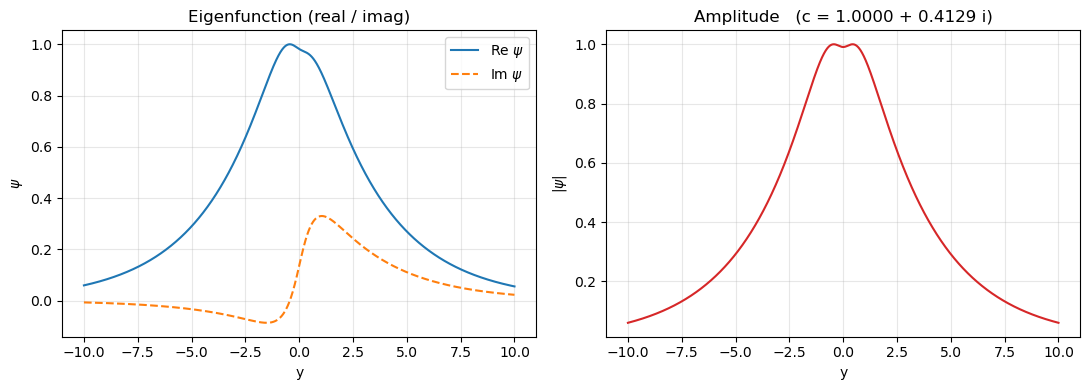

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(Y, psi.real, label=r"Re $\psi$")
ax[0].plot(Y, psi.imag, label=r"Im $\psi$", ls="--")
ax[0].set(xlabel="y", ylabel=r"$\psi$", title="Eigenfunction (real / imag)")
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(Y, np.abs(psi), color="C3")
ax[1].set(xlabel="y", ylabel=r"$|\psi|$",
          title=f"Amplitude   (c = {c.real:.4f} + {c.imag:.4f} i)")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Growth rate vs wavenumber

Continuation in $\alpha$ from the previous solution, for $\beta = 0$.

In [13]:
def solve_mode(alpha2_in, beta_in, c_guess, N_in, verbose=False):
    global alpha2, beta, alpha, N, Y, h, U, sech2, Uyy
    alpha2, beta, alpha = alpha2_in, beta_in, np.sqrt(alpha2_in)
    N = N_in
    Y = np.linspace(ymin, ymax, N); h = Y[1] - Y[0]
    U = 0.5*(1.0 + np.tanh(Y)); sech2 = 1.0/np.cosh(Y)**2
    Uyy = -np.tanh(Y)*sech2
    try:
        c0 = c_guess if c_guess is not None else initial_guess(400, alpha, beta)
        c  = find_eigenvalue(c0, verbose=verbose)
    except Exception:
        return complex("nan","nan"), Y.copy(), None
    if not (np.isfinite(c.real) and np.isfinite(c.imag)):
        return complex("nan","nan"), Y.copy(), None
    # only attempt the eigenfunction when c is meaningfully off the real axis
    psi = eigenfunction(c) if abs(c.imag) > 1e-6 else None
    return c, Y.copy(), psi

alphas  = np.linspace(0.15, 0.95, 40)
omega_i = []
c_prev  = 0.5 + 0.15j        # starting guess for the continuation

for a in alphas:
    try:
        cc, _, _ = solve_mode(a**2, 0.0, c_guess=c_prev, N_in=1500)
    except Exception:
        cc = complex("nan", "nan")

    # accept only unstable modes with c_r inside the velocity range
    if np.isfinite(cc.real) and cc.imag > 1e-5 and 0.0 < cc.real < 1.0:
        omega_i.append(a * cc.imag)
        c_prev = cc
    else:
        omega_i.append(0.0)                  # stable, or the solver missed the mode

omega_i = np.array(omega_i)

## 8. Flat-bottom simulation values for comparison


In [10]:
growth242 = 4.1408e-06
wavelength242 = 71e3
growth242_nodim = (growth242 * 5e3 )/0.2
wavelength242_nondim =  wavelength242/5e3
wavelength242_nondim_lower = 500e3/(8*5e3)
wavelength242_nondim_upper = 500e3/(6*5e3)

growth243 = 1.9347e-06
wavelength243 = 125e3
growth243_nodim = growth243 * 10e3/0.2
wavelength243_nondim =  wavelength243/10e3
wavelength243_nondim_lower = 500e3/(5*10e3)
wavelength243_nondim_upper = 500e3/(3*10e3)

growth244 = 1.3013e-06
wavelength244 = 250e3
growth244_nodim = growth244 * 15e3 /0.2
wavelength244_nondim =  wavelength244/15e3
wavelength244_nondim_lower = 500e3/(3*15e3)
wavelength244_nondim_upper = 500e3/(1*15e3)

In [14]:
ft_size = 16
plt.rcParams.update({'font.size': ft_size})

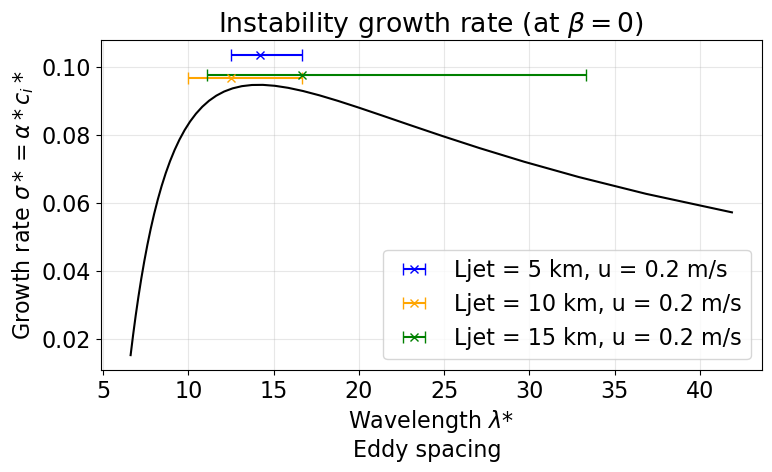

Saved → pv_plots/theory.png


In [15]:
plt.figure(figsize=(8, 5))

plt.plot(np.pi*2/alphas, omega_i,  "-", color='black')

# point 242
xerr242 = [[wavelength242_nondim - wavelength242_nondim_lower],
           [wavelength242_nondim_upper - wavelength242_nondim]]

plt.errorbar(wavelength242_nondim, growth242_nodim,  xerr=xerr242, fmt='x', color='blue', capsize=4, label='Ljet = 5 km, u = 0.2 m/s')

# point 243
xerr243 = [[wavelength243_nondim - wavelength243_nondim_lower],
           [wavelength243_nondim_upper - wavelength243_nondim]]

plt.errorbar(    wavelength243_nondim, growth243_nodim, xerr=xerr243, fmt='x', color='orange', capsize=4, label='Ljet = 10 km, u = 0.2 m/s')

# point 244
xerr244 = [[wavelength244_nondim - wavelength244_nondim_lower],
           [wavelength244_nondim_upper - wavelength244_nondim]]

plt.errorbar( wavelength244_nondim,growth244_nodim, xerr=xerr244, fmt='x',color='green', capsize=4,label='Ljet = 15 km, u = 0.2 m/s')

plt.xlabel(f"Wavelength $\lambda$*\nEddy spacing ")
plt.ylabel(r"Growth rate $\sigma*=\alpha* c_i*$")
plt.title(r"Instability growth rate (at $\beta=0$)")
plt.grid(alpha=.3)

plt.legend()
plt.tight_layout()

OUT_DIR = Path('pv_plots')
OUT_DIR.mkdir(parents=True, exist_ok=True)
fname = f'theory.png'
plt.savefig(OUT_DIR / fname, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved → {OUT_DIR / fname}')

plt.show()